### ANÁLISIS PARTE 4

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Merged_data.csv")

##### 1. RELACIÓN ENTRE EN NÚMERO DE PITSTOPS Y LA POSICIÓN FINAL

Cada parada implica una pérdida de tiempo, por lo tanto procedemos a analizar si hacer más paradas implica posiciones más bajas.

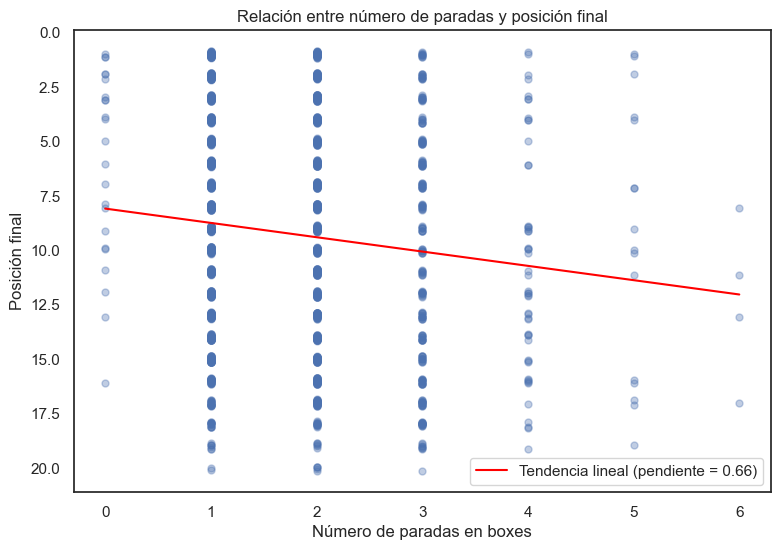

In [44]:
# Carga de datos
plot_df = df.copy()
plot_df['Pos.'] = pd.to_numeric(df['Pos.'], errors="coerce")
plot_df['NPitstops'] = pd.to_numeric(df['NPitstops'], errors="coerce")
plot_df = plot_df.dropna(subset=['Pos.', 'NPitstops']).copy()

# Limpiamos las posiciones para evitar outliers:
plot_df = plot_df[(plot_df['Pos.']>= 1) & (plot_df['Pos.'] <= 40)]

# Creamos el plot
plt.figure(figsize=(9,6))
pos_y = plot_df['Pos.'] + np.random.uniform(-0.15, 0.15, size=len(plot_df))
plt.scatter(plot_df['NPitstops'],pos_y, s=25, alpha=0.35)

# Línea para mostrar la tendencia
z = np.polyfit(plot_df['NPitstops'], plot_df['Pos.'], 1)
p = np.poly1d(z)
xline = np.linspace(plot_df['NPitstops'].min(), plot_df['NPitstops'].max(), 100)
plt.plot(xline, p(xline), color = "red", label = f"Tendencia lineal (pendiente = {z[0]:.2f})")


# Ploteamos
plt.title("Relación entre número de paradas y posición final")
plt.xlabel("Número de paradas en boxes")
plt.ylabel("Posición final")
plt.legend()
plt.gca().invert_yaxis() # Primer posición arriba

plt.show()

Invertimos el eje de las ordenadas con el fin de que se observen las posiciones finales en orden de mejor a peor, de arriba a abajo.                                                                                                                                      
Como se puede observar en el gráfico, existe una correlación inversamente propocional entre el número de paradas y la posición final, lo que quiere decir que cuanto menos paradas hay más probabilidades de no acabar en los últimos puestos. Dicho de otra manera, cuantas menos paradas, hay más probabilidades de acabar en una buena posición. Además, en el gráfico se puede observar por la dispersión de los puntos, que la cantidad de paradas más repetida en los pilotos es entre 1 y 3 paradas.

##### 2. RELACIÓN ENTRE LA DURACIÓN DE LOS PIT-STOPS Y LA POSICIÓN FINAL

Para analizar esta relación hemos dedicido utilizar boxplot para cada una de las posiciones con el fin de observar la distribución y en especial la mediana del tiempo medio de los pit-stops.

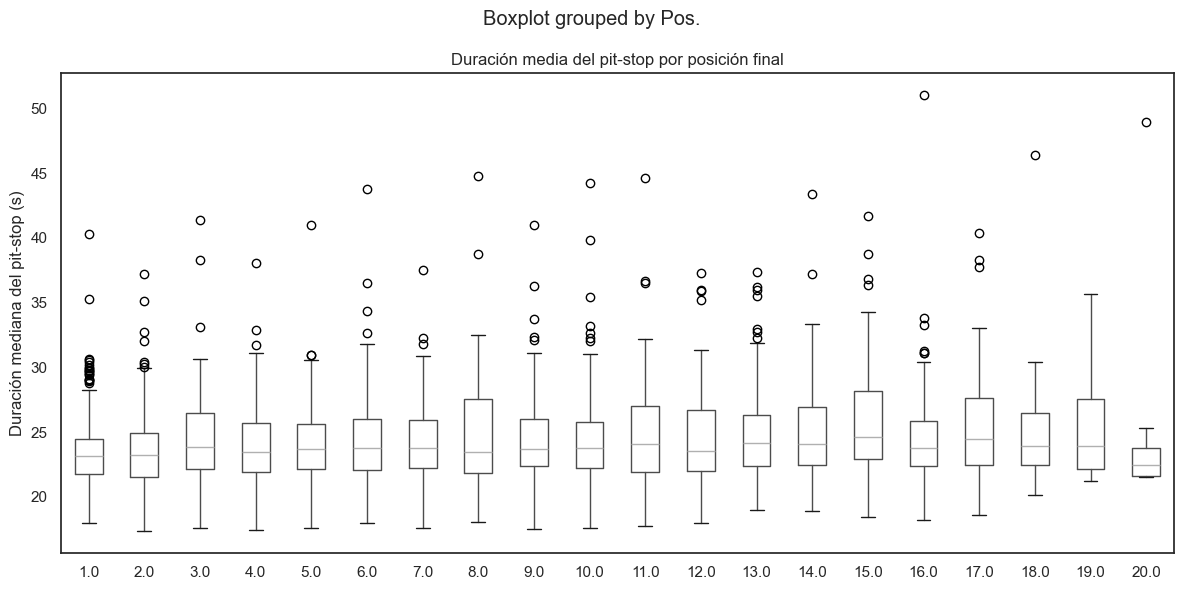

In [45]:
# Carga de datos
plot_df2 = df.copy()
plot_df2['Pos.'] = pd.to_numeric(df['Pos.'], errors="coerce")
plot_df2['MedianPitStopDuration'] = pd.to_numeric(df['MedianPitStopDuration'], errors="coerce")
plot_df2 = plot_df2.dropna(subset=['Pos.', 'MedianPitStopDuration']).copy()

# Limpiamos los datos:
plot_df2 = plot_df2[(plot_df2['Pos.']>= 1) & (plot_df2['Pos.'] <= 20)]
# Ordenamos los datos
plot_df2.sort_values('Pos.', inplace=True)

# Creamos el plot
ax = plot_df2.boxplot(column='MedianPitStopDuration', by='Pos.', figsize=(12,6), grid = False)

# Ploteamos
plt.title("Duración media del pit-stop por posición final")
plt.xlabel("")
plt.ylabel("Duración mediana del pit-stop (s)")
plt.tight_layout()

plt.show()

El gráfico muestra la distribución de la duración de los pitstops para cada una de las posiciones finales. Se puede observar que estas distribuciones son bastante homogéneas, siendo el tiempo medio entre 22 y 26 segundos. A través de este gráfico se puede deducir que no existe una gran relación que cerciore que a paradas más rápidas hay una mayor probabilidad de asegurarse los mejores puestos

##### 3. ¿ES LA POSICIÓN EN LA PARRILLA MÁS DETERMINANTE QUE EL NÚMERO DE PARADAS PARA EL RESULTADO FINAL?

Se busca observar las relaciones entre parámetros, por lo tanto se utiliza una matriz de correlaciones, pudiéndose observar que parámetros influyen a otros.

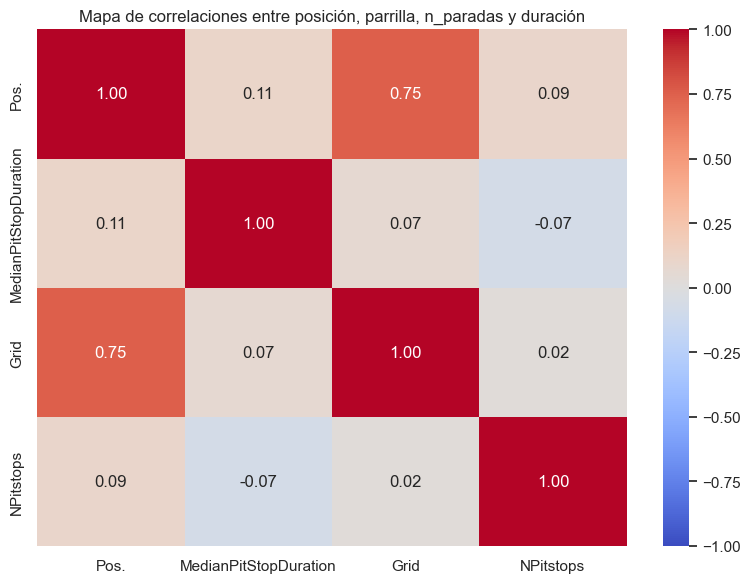

In [46]:
# Carga de datos
plot_df3 = df.copy()

plot_df3['Pos.'] = pd.to_numeric(plot_df3['Pos.'], errors="coerce")
plot_df3['MedianPitStopDuration'] = pd.to_numeric(df['MedianPitStopDuration'], errors="coerce")
plot_df3['Grid'] = pd.to_numeric(df['Grid'], errors="coerce")
plot_df3['NPitstops'] = pd.to_numeric(df['NPitstops'], errors="coerce")

plot_df3 = plot_df3.dropna(subset=['Pos.', 'MedianPitStopDuration', 'Grid']).copy()

variables = plot_df3[['Pos.', 'MedianPitStopDuration', 'Grid', 'NPitstops']].dropna()
# Correlaciones Spearman
corr_spearman = variables.corr(method="spearman")

# Creamos el plot
sns.set(style="white", font_scale=1.0)
plt.figure(figsize=(8,6))
ax = sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap='coolwarm', center=0, vmin=-1, vmax=1)

# Ploteamos
ax.set_title("Mapa de correlaciones entre posición, parrilla, n_paradas y duración")
plt.tight_layout()

plt.show()

En este gráfico se observan las correlaciones que existen entre la posición final (Pos.), la posición de la parrilla (Grid), el número de paradas (NPitstops) y la duración media de las paradas.
Si analizamos los resultados, observamos que la mayor relación que existe es entre la posición de la parrilla y la posición final (0,75) lo que quiere decir que la posición final del piloto está fuertemente relacionado con la posición en la que ha salido.
Por otro lado, la relación entre la posición final y el número de paradas (0,09) y la posición final con la duración de las paradas (0,11) son notablemente más bajas sugiriendo que estos parámetros no tienen tanta influencia en el resultado final de la carrera.
En conclusión, la posición de salida es el parámetro más determinante para ganar la carrera de los evaluados.

##### 4. ¿LOS PILOTOS QUE REALIZAN MENOS PARADAS, OBTIENEN MÁS PUNTOS?

Utilizamos un gráfico de barras con puntos medios por número de paradas, para observar si afecta el número de paradas a la cantidad de puntos obtenidos al final de la carrera.

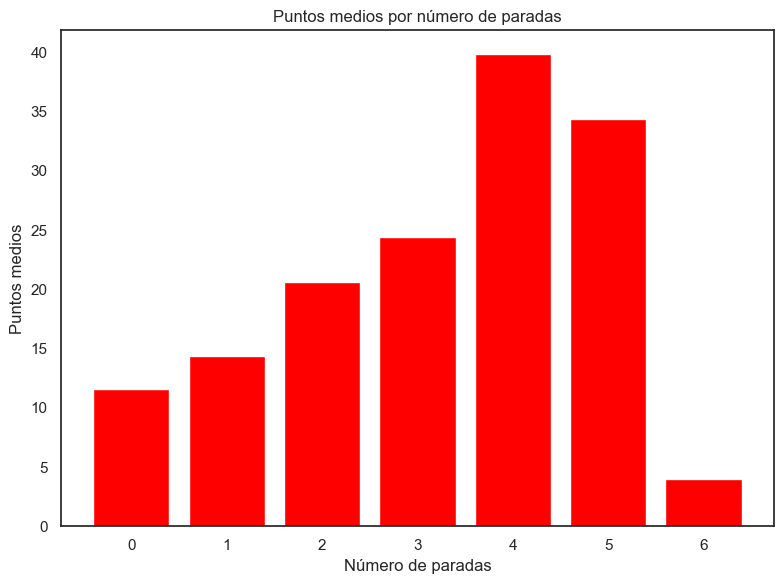

In [47]:
# Carga de datos
plot_df4 = df.copy()

plot_df4['Points'] = pd.to_numeric(df['Points'], errors="coerce")
plot_df4['NPitstops'] = pd.to_numeric(df['NPitstops'], errors="coerce")

# Limpiamos datos para evutar datos anómalos o nulos que afecten al estudio
plot_df4 = plot_df4.dropna(subset=['Points']).copy()
plot_df4 = plot_df4[(plot_df4['Points']>= 0)]

# Se calculan las medias
plot_df4 = plot_df4.groupby('NPitstops')['Points'].mean().reset_index()

# Graficamos
plt.figure(figsize=(8,6))
plt.bar(plot_df4['NPitstops'], plot_df4['Points'], color = "red")
plt.title("Puntos medios por número de paradas")
plt.xlabel("Número de paradas")
plt.ylabel("Puntos medios")
plt.tight_layout()
plt.show()



Se observa en el gráfico que no necesariamente pocas paradas significa mayor probabilidad de más puntos, sino que la mayor cantidad de puntos, de media, se obtienen haciendo cuatro paradas. Pero como se observa,, tanmpoco es bueno hacer muchas pues cuando se baja a seis paradas se ve que la cantidad de puntos baja drásticamente.

##### 5. EVOLUCIÓN DE PODIOS POR TEMPORADA DE LOS EQUIPOS

En este apartado se va a estudiar la evolución de los podiums de los distintos equipos a lo largo de las temporadas con una línea temporal.

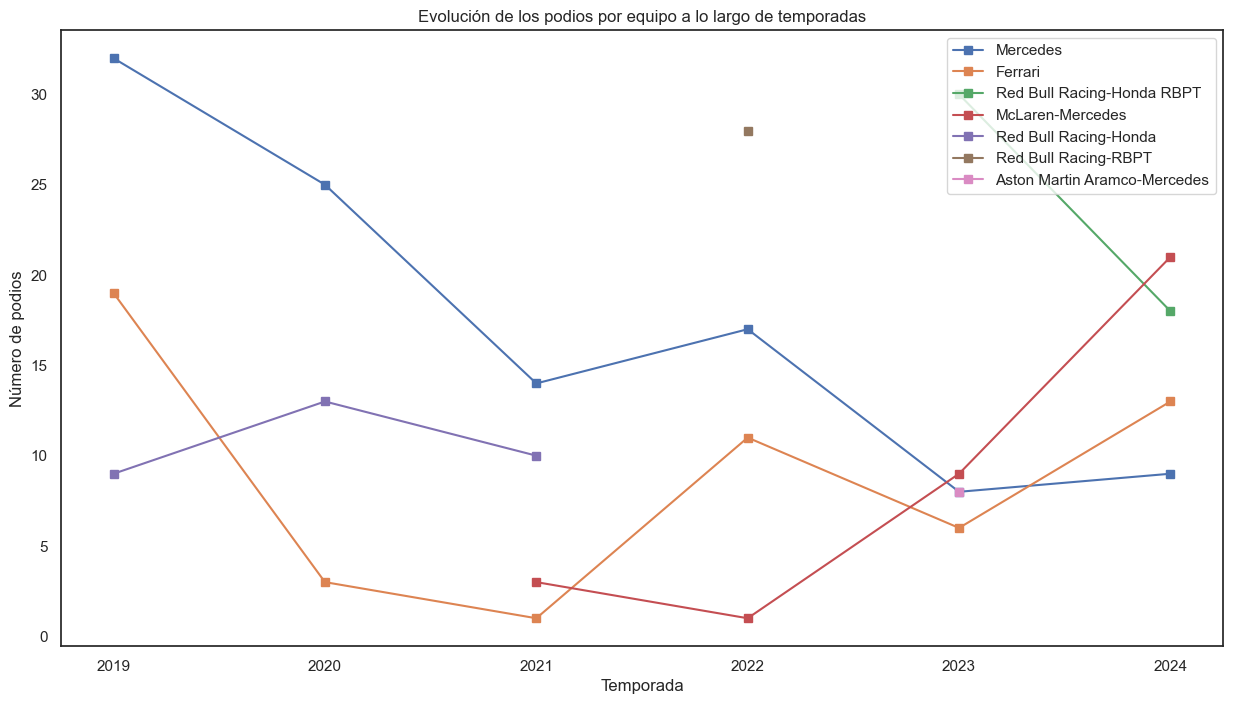

In [55]:
plot_df5 = df.copy()

plot_df5['Pos.'] = pd.to_numeric(df['Pos.'], errors="coerce")
plot_df5['Season'] = pd.to_numeric(df['Season'], errors="coerce")

plot_df5 = plot_df5.dropna(subset=['Pos.', 'Constructor', 'Season'])

# Filtro posiciones válidas
plot_df5 = plot_df5[(plot_df5['Pos.']>=1) & (plot_df5['Pos.']<=3)]

# Agrupo por equipo y temporada
agg = plot_df5.groupby(['Season', 'Constructor']).size().reset_index(name="Podios")

# Seleccionamos a los TOP7 equipos
principales_equipos = agg.groupby('Constructor')['Podios'].sum().sort_values(ascending = False).head(7).index

plot_df = agg[agg['Constructor'].isin(principales_equipos)].copy()

# Dibujar gráfico:
plt.figure(figsize=(15,8))

for equipo in principales_equipos:
    sub = plot_df[plot_df['Constructor']==equipo]
    plt.plot(sub['Season'], sub['Podios'], marker = "s", label = equipo)

plt.title("Evolución de los podios por equipo a lo largo de temporadas")
plt.xlabel("Temporada")
plt.ylabel("Número de podios")
plt.legend()
plt.show()



En el gráfico muestra la evolución a lo largo de las temporadas de los equipos en función de la cantidad de podios obtenidos. Se observa como los dos equipos que se encuentran en todas las temporads son Mercedes y Ferrari. El primero, ha ido perdiendo podios a lo largo de los años, mientras que el segundo, tras perder podios en las temporadas de 2020, 2021, poco a poco a vuelto aproximadamente a sus resuiltados de la temporada de 2019.
El equipo de Red Bull bajo distintos nombres, también presenta una dominancia a lo largo de los años.
Cabe destacar el año 2023-24 cuando Aston Martin aumentó su número de podios gracias a su mejora en la temporada.